In [48]:
# Import libraries

#--- Standard Libraries: general utilities ---
import difflib # Compare text and find close matches
import json # Read and write JSON data
import operator # Function versions of operators, such as add for state reducers
import os # Access environment variables
from datetime import datetime # Create and format timestamps
from pathlib import Path # Work with file paths

# --- Standard library: type hints ---
from typing import Annotated, Literal, TypedDict # Define state schemas and restrict allowed values

# --- Configuration ---
from dotenv import load_dotenv # Load API keys and settings from .env

# --- Data handling and HTTP requests ---
import pandas as pd # Load and manipulate tabular data
import requests # Call external HTTP APIs

# --- LLM providers and clients ---
from langchain_openai import ChatOpenAI # LangChain chat model for OpenAI-compatible APIs
from openrouter import OpenRouter # OpenRouter SDK client

# --- LangChain: agents and tools
from langchain.agents import create_agent # Build an agent that can call tools
from langchain.agents.middleware import HumanInTheLoopMiddleware # Pause tool calls for human review
from langchain_core.tools import tool # Turn Python functions into agent tools

# --- LangGraph: workflow orchestration ---
from langgraph.checkpoint.memory import InMemorySaver # Save graph state in memory between steps
from langgraph.graph import END, START, StateGraph # Define graph state, nodes, edges, and entry/exit points
from langgraph.types import Command, RetryPolicy, Send # Resume or redirect runs, retry failed nodes, and fan out work

# --- Langfuse: tracing and observability ---
from langfuse import get_client # Access the configured Langfuse client
from langfuse.langchain import CallbackHandler # Trace LangChain and LangGraph runs in Langfuse

# --- Local modules ---
from week2day1_payout import Benefit, Line, Payout, work_out_payout # Payout data models and calculation logic


### Connect to OpenRouter and Langfuse

In [49]:
load_dotenv(override=True)

openrouter_api_key = os.getenv('OPENROUTER_API_KEY')
OPENROUTER_BASE_URL = 'https://openrouter.ai/api/v1'

if openrouter_api_key:
    print("OpenRouter API Key found and starts with:", openrouter_api_key[:5])
else:
    print("OpenRouter API Key not found") 

langfuse = get_client()
langfuse_handler = CallbackHandler()

if langfuse.auth_check():
    print("Connected to Langfuse")
else:
    print("Failed to connect to Langfuse")


OpenRouter API Key found and starts with: sk-or
Connected to Langfuse


## Part 1: A judge with a reference answer

In [50]:
DATA = Path("../../../data")

def load(name): # Load a JSON seed file by name
    """ Read one of the JSON seed files"""
    return json.loads((DATA / name).read_text(encoding='utf-8'))

def get_sample_data(tiny=False, held_out=False): # Get sample data from the JSON seed files
    """ Return a list of claims, and the handlers' decisions on them keyed by claim id. """
    claims = load('evals/held_out_claims.json' if held_out else 'claims.json')
    decisions = load('evals/held_out_decisions.json' if held_out else 'evals/decisions.json')
    if tiny:
        chosen = {decision['claim_id'] for decision in decisions if decision['tiny']}
        claims = [claim for claim in claims if claim['claim_id'] in chosen]
        decisions = [decision for decision in decisions if decision['tiny']]
    labels = {decision['claim_id']: decision for decision in decisions}
    return claims, labels

In [51]:
TINY = False

evaluation_claims, evaluation_labels = get_sample_data(tiny=TINY) # Load evaluation claims and labels
held_out_claims, held_out_labels= get_sample_data(tiny=TINY, held_out=True) # Load held-out claims and labels

claims = {claim['claim_id']: claim for claim in evaluation_claims + held_out_claims} # Combine evaluation and held-out claims into a dictionary keyed by claim_id
labels = evaluation_labels | held_out_labels # Combine evaluation and held-out labels into a single dictionary
policies = {policy['policy_id']: policy for policy in load('policies.json')} # Load policies into a dictionary keyed by policy_id
policy_wording = (DATA / 'policy_wording.md').read_text(encoding='utf-8') # Read the policy wording from the markdown file

SETS = {'evaluation': list(evaluation_labels), 'held_out': list(held_out_labels)} # Defines the sets of claim IDs for evaluation and held-out data
print(f"{len(SETS['evaluation'])} evaluation claims and {len(SETS['held_out'])} held-out claims") # Print the number of evaluation and held-out claims

25 evaluation claims and 25 held-out claims


### The handler's reasons

In [52]:
# Load the whole queue, in case TINY is True
queue_claims, queue_labels = get_sample_data() # Load the full queue of claims and labels
handler = queue_labels['CLM-1001'] # Get the handler for the claim with ID 'CLM-1001'

print(f"Decision: {handler['decision']} ${handler['payout']:,.2f}") # Print the decision and payout for the handler of the claim with ID 'CLM-1001'
print(f"Reason: {handler['reason']}") # Print the reason for the decision of the handler of the claim with ID 'CLM-1001'
print(f"Reference: {handler['reference']}") # Print the reference for the decision of the handler of the claim with ID 'CLM-1001'

Decision: approve $420.00
Reason: The carrier canceled the flight for a crew problem and the delay was 19 hours, well past the 6 hour waiting period on Premium. The hotel, meals and taxis are reasonable and all have receipts. The total is inside the $800 maximum.
Reference: Policy wording, section 3


### A reference-guided judge

In [53]:
JEV = 'typesafe/jev-1.13' # Define the JEV version to be used

# Jev numbers the grade by their position in the list, so F is 0 and A is 3
RUBRIC = {
    'F': "different ground from the handler's reason, or it contradicts the handler's reason", 
    'C': "partly the same as the handler's reason: one of the handler's grounds or the section is missing, or it adds a ground the handler did not give",
    'B': "the same grounds and the same section of the policy wording as the handler's reason",
    'A': "the same grounds and section as the handler's reason, and clearly better expressed: clearer for the customer, with the section and the figures, shorter, and no jargon",
}
GRADES = list(RUBRIC)

JUDGE_QUESTIONS = {
    'grade': {
        'type': 'score',
        'instructions': 'An expert claims handler decided a travel insurance claim and gave `handler.reason`, resting on `handler.reference`. Grade how well `agent.rationale` explains the same decision.',
        'criteria': [f"{letter}: {text}" for letter, text in RUBRIC.items()],
    },
    'same_grounds': {'type': 'noul', 'instructions': '`agent.rationale` gives the same main grounds for the decision as `handler.reason`'},
    'same_section': {'type': 'noul', 'instructions': '`agent.rationale` refers to the same section of the policy wording as `handler.reference`'},
}

openrouter_decisions = OpenRouter(api_key=openrouter_api_key, timeout_ms=60_000)

def judge(rationale, decision, expected):
    """ Ask Jev to grade a rationale against the handler's reason."""
    state = {
        'handler':
            {
                'decision': expected['decision'], 
                'reason': expected['reason'],
                'reference': expected['reference']
            },
        'agent':
        {
            'decision': decision,
            'rationale': rationale,
        }
    }
    response = openrouter_decisions.alpha.decisions.create(model=JEV,
                                                          state=state,
                                                          questions=JUDGE_QUESTIONS)
    answers = response.answers
    probabilities = answers['grade'].probabilities
    most_likely = max(probabilities, key=probabilities.get)
    return {
        'grade': answers['grade'].score,
        'letter': GRADES[int(most_likely)],
        'same_grounds': answers['same_grounds'].noul,
        'same_section': answers['same_section'].noul,
        'judge_cost': response.usage.cost
    }


### Checking the judge

In [54]:
other_claim = queue_labels['CLM-1003']
tests ={
    "The handler's reason": f"{handler['reason']} ({handler['reference']})",
    "a different claim's reason": other_claim['reason'],
    "Vague": "The flight was cancelled and the customer stayed in a hotel, so we approve the claim.",
    "Clearer than the handler": "Approved under section 3: the crew problem delayed your flight by 19 hours, past the 6 hour waiting period on Premium. We pay the $420 for your hotel, meals and taxis in full, since every item has a receipt and the total is under the $800 limit.",
}

rows = []
for name, rationale in tests.items():
    rows.append({'rationale': name, 
                **judge(rationale,  
                        'approve', 
                        handler)})

pd.DataFrame(rows).round(2)

,rationale,grade,letter,same_grounds,same_section,judge_cost
0,The handler's reason,2.03,B,0.99,0.99,0.0
1,a different claim's reason,0.00,F,0.02,0.07,0.0
2,Vague,0.89,C,0.26,0.19,0.0
3,Clearer than the handler,2.84,A,0.98,0.98,0.0


## Part 2: Version 1 and its scores

### The configuration

In [55]:
INSTRUCTIONS = """ You are a claims handler at UnderCover Travel Insurance. Decide the claim you are given, using the policy
wording below and the customer's policy record.


Choose one decision:
- approve: the wording covers the claim and the required documents are attached. Work out the payout using section 10.
- decline: the wording does not cover the claim.
- refer: a colleague needs to look at it, because a required document is missing, or the story and the documents disagree, or the wording does not settle the question.

Use your tools to record your decision.
Use the payout tool to work out the payout on an approved claim, and record the payout it returns.
"""

versions = [
    {
        'version': 1,
        'instructions': INSTRUCTIONS,
        'model': 'openai/gpt-6-luna',
        'reasoning_effort': 'low'
    }]
current = 1

### The claim agent


In [56]:
recorded = {}

@tool(parse_docstring=True) #  This tool will be used to record decisions made on claims.
def record_decision(claim_id: str, rationale: str, decision: Literal['approve', 'decline', 'refer'], payout: float) -> str:
    """ Record the decision on a claim in the claims system.
    
    Args: 
        claim_id: The claim's id
        rationale: 2-3 sentences explaining the decision along with the relevant section of the policy 
        decision: The decision on the claim
        payout: The amount to pay in US dollars, or 0 for a decline or a referral
    """

    if claim_id in recorded:
        return f"A decision is already recorded for claim{claim_id}, and decisions are final"
    if decision == 'approve' and payout <= 0:
        return "An approval needs a payout above zero"
    recorded[claim_id] = {'decision': decision,
                          'payout': payout,
                          'rationale': rationale}
    return f"Recorded {decision} on {claim_id}"

@tool(parse_docstring=True) # This tool will be used to retrieve recorded decisions.
def calculate_payout(policy_id: str, benefit: Benefit, lines: list[Line], paid_by_others: float = 0.0) -> float:
    """ Work out the payout on an approved claim with UnderCover's payout rules. 
    
    Args:
        policy_id: the customer's policy id
        benefit: the benefit the claim is paid under
        lines: The covered items and expenses, one for each line of the claim, with any excluded ones left out. A pair or a set counts as one item
        paid_by_others: Anything a carrier, hotel or other party has paid or refunded for the same loss

    Returns: 
        The calculation, the payout and whether it needs sign-off
    """

    return work_out_payout(policies[policy_id], benefit, lines, paid_by_others)


In [57]:
def make_user_prompt(claim): # Generate a user prompt for a given claim
    """ The customer's policy record and the claim as JSON."""
    policy = policies[claim['policy_id']]
    return f"""# Policy record
    
    {json.dumps(policy, indent=2)}
    
    # Claim 

    {json.dumps(claim, indent=2)}
    """

def make_agent(config): # Generate an agent prompt for a given claim
    """ Build the claim agent for one version of the configuration. """
    model = ChatOpenAI(
        model=config['model'],
        base_url=OPENROUTER_BASE_URL,
        api_key=openrouter_api_key,
        reasoning_effort=config['reasoning_effort'],
        timeout=120, 
        max_retries=5
    )
    return create_agent(
        model=model,
        tools=[record_decision, 
                calculate_payout],
        system_prompt=f"{config['instructions']}\n{policy_wording}\n"
    )

### The dispatcher

In [58]:
class Dispatch(TypedDict): # Dispatcher state for one run
    """ What the dispatcher keeps for one run."""

    config: dict
    claims: list[str]
    results: Annotated[list, operator.add]

def fan_out(state: Dispatch): # Fan out claims for processing
    """ Send each claim to a claim agent, with the configuration to use. """
    return [Send('work_claim', {'claim_id': claim_id, 'config': state['config']}) for claim_id in state['claims']]

def work_claim(task): # Process a single claim
    """ Run a claim agent on one claim and return its result. """
    claim_id = task['claim_id']
    agent = make_agent(task['config'])
    started = datetime.now()
    result = agent.invoke(
        {
            'messages': 
            [
                {'role': 'user',
                'content': make_user_prompt(claims[claim_id])
                }
            ]
        }
    )
    answer = recorded.get(claim_id,
                            {'decision': 'refer',
                            'payout': 0.0,
                            'rationale': 'Nothing recorded'})
    cost = sum(message.response_metadata['token_usage']['cost'] for message in result['messages'] if message.type == 'ai')
    return {'results': [{'claim_id': claim_id, **answer, 'cost': cost, 'started': started, 'finished': datetime.now()}]}

builder = StateGraph(Dispatch) # Build the state graph for dispatching claims 
builder.add_node('work_claim', work_claim, retry_policy=RetryPolicy(max_attempts=3))
builder.add_conditional_edges(START, fan_out, ['work_claim'])
builder.add_edge('work_claim', END)
dispatcher = builder.compile()

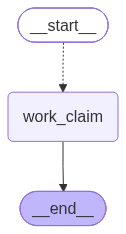

In [59]:
dispatcher

### Scoring a run

In [60]:
WRONGFUL_DECLINE = 1500
NEEDLESS_REFERRAL = 50

def is_right(answer, expected): # Check if the answer is correct
    """ True when the decision matches the handler's and the payout is within a dollar. """
    return answer['decision'] == expected['decision'] and abs(answer['payout'] - expected['payout']) <= 1

def mistake_cost(answer, expected): # Calculate the cost of a mistake
    """ What the agent's answer costs UnderCover, against the handler's decision. """
    if answer['decision'] == expected['decision']:
        return abs(answer['payout'] - expected['payout']) if answer['decision'] == 'approve' else 0
    if answer['decision'] =='decline':
        return WRONGFUL_DECLINE
    if answer['decision'] == 'approve':
        return answer['payout']
    return NEEDLESS_REFERRAL

In [61]:
def score_table(results): # Generate a table summarizing the scores from the results
    """ One row for each claim: the agent's answer besides the handler's, with the judge's grade, cost, and time. """
    rows =[]
    for answer in results:
        expected = labels[answer['claim_id']]
        rows.append({
            'claim_id': answer['claim_id'],
            'handler': expected['decision'],
            'agent': answer['decision'],
            'handler_payout': expected['payout'],
            'agent_payout': answer['payout'],
            'right': is_right(answer, expected),
            'mistake_cost': mistake_cost(answer, expected),
            **judge(answer['rationale'], answer['decision'], expected),
            'llm_cost': answer['cost'],
            'seconds': (answer['finished'] - answer['started']).total_seconds(),
            'rationale': answer['rationale']
        })
    return pd.DataFrame(rows).sort_values('claim_id')

def run_scores(table): # Calculate summary statistics from the score table
    """ The scores for a whole run: quality, cost, and time."""
    return {
        'decision_accuracy': (table['agent'] == table['handler']).mean(),
        'accuracy': table['right'].mean(),
        'cost_of_mistakes': table['mistake_cost'].sum(),
        'grade': table['grade'].mean(),
        'cost_per_claim': table['llm_cost'].mean(),
        'seconds_per_claim': table['seconds'].mean()
    }


### Evaluating a version

In [62]:
tables ={}
scoreboard =[]
spent =0.0

def evaluate(config, set_name): # Evaluate the performance of a given configuration on a specific dataset
    """ Run one version of the configuration on one set, score it and add it to the scoreboard."""
    global spent
    recorded.clear()
    run_name = f"Version {config['version']} on the {set_name} set"
    result = dispatcher.invoke({'config': config, 'claims': SETS[set_name]},
                               {'max_concurrency': 25, 'callbacks': [langfuse_handler], 'run_name': run_name}) 
    table = score_table(result['results'])
    scores = run_scores(table)
    spent += table['llm_cost'].sum() + table['judge_cost'].sum()
    tables[(config['version'], set_name)] = table
    scoreboard.append({'version': config['version'], 'set': set_name, **scores})
    print(f"{run_name}: accuracy {scores['accuracy']:.2f}, grade {scores['grade']:.2f}, "
          f"${scores['cost_per_claim']:.5f} and {scores['seconds_per_claim']:.1f} seconds a claim")
    return scores

### Version 1

In [63]:
evaluate(versions[0], 'evaluation')
evaluate(versions[0], 'held_out')

pd.DataFrame(scoreboard)

Version 1 on the evaluation set: accuracy 0.76, grade 1.14, $0.00036 and 5.1 seconds a claim
Version 1 on the held_out set: accuracy 0.60, grade 1.21, $0.00033 and 5.4 seconds a claim


,version,set,decision_accuracy,accuracy,cost_of_mistakes,grade,cost_per_claim,seconds_per_claim
0,1,evaluation,0.76,0.76,663.0,1.1400,0.000358,5.088958
1,1,held_out,0.64,0.60,2705.0,1.2116,0.000329,5.433520


In [64]:
table = tables[(1, 'evaluation')]
table[~table['right']][['claim_id', 
                        'handler', 
                        'agent', 
                        'handler_payout', 
                        'agent_payout',
                        'letter',
                        'grade',
                        'rationale',
                        ]].round(2)

,claim_id,handler,agent,handler_payout,agent_payout,letter,grade,rationale
1,CLM-1002,approve,refer,580.0,0.0,F,0.26,The carrier report satisfies the required repo...
12,CLM-1013,decline,approve,0.0,64.0,F,0.19,The seven-hour delay exceeds the Economy plan’...
17,CLM-1018,refer,approve,0.0,330.0,F,0.35,"The theft occurred during the covered trip, an..."
18,CLM-1019,refer,approve,0.0,98.0,F,0.03,The carrier confirms a nine-hour delay caused ...
19,CLM-1020,approve,refer,240.0,0.0,F,0.03,The loss falls within the Baggage and Personal...
24,CLM-1025,refer,approve,0.0,71.0,F,0.09,Approve under section 3: the Economy waiting p...


### How much do the scores move? 

In [65]:
evaluate(versions[0], 'held_out')

pd.DataFrame(scoreboard).round(4)

Version 1 on the held_out set: accuracy 0.72, grade 1.39, $0.00024 and 5.6 seconds a claim


,version,set,decision_accuracy,accuracy,cost_of_mistakes,grade,cost_per_claim,seconds_per_claim
0,1,evaluation,0.76,0.76,663.0,1.1400,0.0004,5.0890
1,1,held_out,0.64,0.60,2705.0,1.2116,0.0003,5.4335
2,1,held_out,0.72,0.72,5036.0,1.3920,0.0002,5.6499


## Part 3: One round of improvement

In [66]:
OBJECTIVES = {
    'accuracy': 0.1,
    'grade': 1.0
}
NOISE = {
    'accuracy': 0.1,
    'grade': 0.15,
    'cost_per_claim': 0.15,
    'seconds_per_claim': 0.15
}
TOLERANCE = {
    'accuracy': 0.1,
    'grade': 0.15,
    'cost_per_claim': 1.0,
    'seconds_per_claim': 0.25
}
BUDGET = 0.50

ALLOWED_MODELS = {
    'openai/gpt-6-luna':
    {
        'reasoning_efforts': 
                            ['none', 
                            'low', 
                            'medium'],
        'price per million tokens': '$0.10 in, $0.50 out' 
    },
    'google/gemini-3.5-flash-lite':
    {
        'reasoning_efforts':
                            [
                                'low',
                                'medium'
                            ],
        'price per million tokens': '$0.30 in, $2.50 out'
    },
    'deepseek/deepseek-v4.1-flash':
    {
        'reasoning_efforts':
        [
            'minimal',
            'low'
        ],
        'price per million tokens': '$0.30 in, $1.20 out'
    }  
}


In [67]:
def compare(new, old): # Compare new and old scores to see which improved or worsened
    """ Which scores got better by more than the noise, and which got worse by more than the tolerance. """
    better, worse =[], []
    for name in ['accuracy', 'grade']:
        if new[name] > old[name] + NOISE[name]:
            better.append(name)
        if new[name] < old[name] - TOLERANCE[name]:
            worse.append(name)
    for name in ['cost_per_claim', 'seconds_per_claim']:
        if new[name] < old[name] * (1 - NOISE[name]):
            better.append(name)
        if new[name] > old[name] * (1 + TOLERANCE[name]):
            worse.append(name)
    return better, worse

def keep_or_roll_back(new, old): # Decide whether to keep a new version based on its scores and the current version's average
    """ Decide whether to keep a new version from its held-out scores and the current version's average. """
    missed = [name for name, floor in OBJECTIVES.items() if new[name] < floor]
    better, worse = compare(new, old)
    if missed:
        return False, f"it missed the objectives on {', '.join(missed)}"
    if worse:
        return False, f"{', '.join(worse)} got worse"
    if not better:
        return False, "no score improved by more than the the noise"
    return True, f"{', '.join(better)} improved"

### The improver's tool

In [68]:
rounds = []

def latest(version, set_name): # Get the most recent scores for a version on a set
    """ The most recent scores for a version on a set."""
    return [row for row in scoreboard if row['version'] == version and row['set'] == set_name][-1]

def average(version, set_name): # Get the average scores for a version on a set
    """ the average of a version's scores over all its runs on a set."""
    runs = pd.DataFrame([row for row in scoreboard if row['version'] == version and row['set'] == set_name])
    return runs.drop(columns=['version', 'set']).mean().to_dict()

def beside_handler(table): # Handle the beside operation for a table
    """ Each claim in a table with the agent's answer beside the handler's and the judge's grade. """
    rows = []
    for row in table.to_dict('records'):
        expected = labels[row['claim_id']]
        rows.append({
            'claim-id': row['claim_id'],
            'summary': claims[row['claim_id']]['summary'],
            'agent': {'decision': row['agent'],
                       'payout': row['agent_payout'], 
                       'rationale': row['rationale']},
            'handler': {'decision': expected['decision'],
                        'payout': expected['payout'],
                        'reason': expected['reason'],
                        'reference': expected['reference']},
            'judge': {'grade': round(row['grade'], 2),
                      'letter': row['letter']}, })
    return rows

def mistakes(version): # Get the mistakes and the lowest graded correct ones
    """ The evaluation claims a version got wrong, and the five right ones with the lowest grades. """
    table = tables[(version, 'evaluation')]
    weakest = table[table['right']].sort_values('grade').head(5)
    return {"wrong": beside_handler(table[~table['right']]), 'explained_least_well': beside_handler(weakest)}
    

In [69]:
@tool
def read_results() -> str:  # Read the results from the scoreboard
    """Read the current configuration, scores, evaluation mistakes, earlier rounds,
    objectives, budget, and allowed models."""
    config = versions[current - 1]
    report = {
        'current_version': config,
        'scores': {set_name: average(current, set_name) for set_name in SETS},
        'evaluation_set': mistakes(current),
        'earlier_rounds': rounds,
        'objectives_on_the_held_out_set': OBJECTIVES,
        'noise': NOISE,
        'tolerance': TOLERANCE,
        'rule': 'A new version is kept when it meets the objectives, at least one score improves by more than the noise and none gets worse by more than the tolerance',
        'budget_left': round(BUDGET - spent, 4),
        'models_allowed': ALLOWED_MODELS,
    }
    return json.dumps(report, indent=2, default=str)

In [70]:
@tool(parse_docstring=True)
def propose_change(instructions: str, model: str, reasoning_effort: str, reason: str) -> str: # Propose a change based on the given instructions, model, reasoning effort, and reason
    """Propose a new version of the claim agent's configuration. A human reviews it before it's saved.

    Args:
        instructions: The claim agent's complete instructions 
        model: One of the models allowed
        reasoning_effort: A reasoning level allow for that model
        reason: Why this change should improve the scores
    """

    if reasoning_effort not in ALLOWED_MODELS.get(model, {}).get('reasoning_efforts', []):
        return f"{model} at {reasoning_effort} is not allowed. Choose from the models allowed."
    version = len(versions) + 1
    versions.append({
        'version': version,
        'instructions': instructions,
        'model': model,
        'reasoning_effort': reasoning_effort,
        'reason': reason
    })
    return f"Saved as version {version}. Run the evaluation next."

In [71]:
@tool
def run_evaluation() -> str:
    """ Run the newest version once on the evaluation set and twice on the held-out set, then keep it or roll it back. """
    global current
    config = versions[-1]
    if config['version'] == current or any(r['version'] == config['version'] for r in rounds):
        return "There's no new version to evaluate. Propose a change first."
    estimate = 3 * len(SETS['held_out']) * max(row['cost_per_claim'] for row in scoreboard)
    if spent + estimate > BUDGET:
        return f"Refused: the evaluation could cost about ${estimate:.2f} and ${BUDGET - spent:.2f} of the budget is left"
    before = average(current, 'held_out')
    evaluate(config, 'evaluation')
    evaluate(config, 'held_out')
    evaluate(config, 'held_out')
    after = average(config['version'], 'held_out')
    keep, why = keep_or_roll_back(after, before)
    rounds.append({
        'round': len(rounds) + 1, 'recipe_version': len(recipes), 'version': config['version'],
        'model': config['model'], 'reasoning_effort': config['reasoning_effort'], 'reason': config['reason'],
        'kept': keep, 'why': why, 'held_out_before': before, 'held_out_after':after
    })
    if keep:
        current = config['version']
    verdict = 'Kept' if keep else 'Rolled back' 
    scores = {'held_out_before': before, 'held_out_after': after, 'evaluation_after': latest(config['version'], 'evaluation')}
    return f"{verdict} version {config['version']}: {why}. Version {current} is now the current version.\n{json.dumps(scores, indent=2)}"

In [72]:
recipes = []

@tool(parse_docstring=True) # Propose a new recipe with a reason for the check
def propose_recipe(recipe: str, reason: str) -> str:
    """ Propose a new version of your recipe for improving the claim agent. A human reviews it before it's saved. 
    
    Args:
        recipe: The proposed recipe for improving for improving the claim agent. A human reviews it before it's saved.
        reason: What this round showed, and why the new recipe should lead to better changes
    """
    recipes.append(recipe)
    return f"Saved as recipe version {len(recipes)}."

    

### The recipe

In [73]:
RECIPE = """ 
1. Call read_results to see how the current version is doing and which evaluation claims it got wrong or explained poorly.
2. For each of those claims, add a rule to the instructions that would make the agent get that claim right.
3. Call propose_change with the new instructions, keeping the same model and reasoning level.
4. Call run_evaluation to test the new version on both sets.
5. Improve this recipe, so that the next round makes a better change. Look at what happened in this round and in earlier rounds, then call propose_recipe with the new recipe. Keep this as the last step of the new recipe.
"""

recipes.append(RECIPE)


### The improver

In [74]:
improver_model = ChatOpenAI(model='openai/gpt-6-luna',
                            base_url=OPENROUTER_BASE_URL,
                            api_key=openrouter_api_key,
                            reasoning_effort='medium',
                            timeout=300,
                            max_retries=5)
approval = HumanInTheLoopMiddleware(interrupt_on={
    'propose_change': {'allowed_decisions': ['approve', 
                                             'reject']},
    'propose_recipe': {'allowed_decisions': ['approve',
                                             'reject']},
})

def make_improver(recipe): # Create an improver agent using the given recipe
    """ Build the improver with a recipe as its instructions."""
    system_prompt = f"""You improve the configuration of UnderCover's claim agent, an AI agent that decides travel insurance claims.
    The claim agent sees its instructions, the policy wording, the customer's policy record and the claim. It doesn't see the claims
    manual or the customer's history.Follow your recipe one step at a time.
    
    # Your recipe

    {recipe}
"""
    return create_agent(model=improver_model,
                        tools=[read_results,
                              propose_change,
                              run_evaluation,
                              propose_recipe],
                        system_prompt=system_prompt,
                        middleware=[approval],
                        checkpointer=InMemorySaver())

In [75]:
def show_changed_lines(old, new):
    """ Print the lines that differ between two texts."""
    for line in difflib.unified_diff(old.splitlines(), 
                                     new.splitlines(),
                                     lineterm="",
                                     n=0):
        if not line.startswith(("---", "+++", "@@")):
            print(line)

def show_proposal(result):
    """ Show the change the improver is waiting for us to approve."""
    if '__interrupt__' not in result:
        print("The improver finished without a proposal. Its last message:")
        print(result['messages'][-1].content)
        return
    request = result["__interrupt__"][0].value["action_requests"][0]
    args = request['args']
    if request['name'] =='propose_change':
        old = versions[current - 1]
        print(f"Model: {old['model']} at {old['reasoning_effort']}, proposed {args['model']} at {args['reasoning_effort']}\n")
        show_changed_lines(old['instructions'], args['instructions'])
    else:
        print(f"Recipe version {len(recipes)}, proposed version {len(recipes) + 1}\n")
        show_changed_lines(recipes[-1], args['recipe'])
    print(f"\nReason: {args.get('reason', '(the model gave no reason)')}")

### Round 1

In [76]:
session = f"Improvement {datetime.now():%Y-%m-%d %H:%M}"
improver = make_improver(recipes[-1])
round_1 = {'configurable': 
           {
               'thread_id': 'round-1'
           },
           'callbacks': [langfuse_handler],
           'run_name': 'Improver round 1',
           'metadata': 
                    {'langfuse_session_id': session}}
result = improver.invoke(
    {
        'messages':
        [
            {
                'role': 'user',
                'content': 'Please carry out one round of your recipe'
            }
        ]
    }, round_1)
show_proposal(result)

Model: openai/gpt-6-luna at low, proposed openai/gpt-6-luna at low

- You are a claims handler at UnderCover Travel Insurance. Decide the claim you are given, using the policy
-wording below and the customer's policy record.
-
+You are a claims handler at UnderCover Travel Insurance. Decide the claim you are given, using the policy wording below and the customer's policy record.
-Use your tools to record your decision.
-Use the payout tool to work out the payout on an approved claim, and record the payout it returns.
+Use your tools to record your decision. Use the payout tool to work out the payout on an approved claim, and record the payout it returns.
+
+Claim-handling rules:
+- Apply waiting periods by comparing the actual elapsed delay with the plan's stated minimum. A delay qualifies only if it reaches that minimum; do not treat a shorter delay as qualifying. Calculate across midnight when needed.
+- For trip delay, check that the cause is one of the covered causes and that the c

In [77]:
APPROVE = Command(resume={'decisions': [
    {
        'type': 'approve'
    }
]})
result = improver.invoke(APPROVE, round_1)
pd.DataFrame(scoreboard).round(4)

Version 2 on the evaluation set: accuracy 0.84, grade 1.51, $0.00039 and 5.7 seconds a claim
Version 2 on the held_out set: accuracy 0.68, grade 1.61, $0.00037 and 5.5 seconds a claim
Version 2 on the held_out set: accuracy 0.80, grade 1.59, $0.00027 and 5.1 seconds a claim


,version,set,decision_accuracy,accuracy,cost_of_mistakes,grade,cost_per_claim,seconds_per_claim
0,1,evaluation,0.76,0.76,663.0,1.1400,0.0004,5.0890
1,1,held_out,0.64,0.60,2705.0,1.2116,0.0003,5.4335
2,1,held_out,0.72,0.72,5036.0,1.3920,0.0002,5.6499
3,2,evaluation,0.88,0.84,843.0,1.5128,0.0004,5.6848
4,2,held_out,0.76,0.68,4230.0,1.6144,0.0004,5.5383
5,2,held_out,0.84,0.80,2394.0,1.5932,0.0003,5.0563


In [78]:
def show_rounds():
    """ one row for each round: the version it tried, the held_out scores before and after, and the verdict."""
    rows =[]
    for r in rounds:
        rows.append({
            'round': r['round'],
            'recipe': r['recipe_version'],
            'version': r['version'],
            'model': r['model'],
            'reasoning': r['reasoning_effort'],
            'accuracy_before': r['held_out_before']['accuracy'], 
            'accuracy_after': r['held_out_after']['accuracy'],
            'grade_before': r['held_out_before']['grade'],
            'grade_after': r['held_out_after']['grade'],
            'kept': r['kept'], 
            'why': r['why']
        })
    return pd.DataFrame(rows).round(2)
show_rounds()

,round,recipe,version,model,reasoning,accuracy_before,accuracy_after,grade_before,grade_after,kept,why
0,1,1,2,openai/gpt-6-luna,low,0.66,0.74,1.3,1.6,True,grade improved


## Part 4: Improving the improver

In [79]:
show_proposal(result)

Recipe version 1, proposed version 2

- 
-1. Call read_results to see how the current version is doing and which evaluation claims it got wrong or explained poorly.
-2. For each of those claims, add a rule to the instructions that would make the agent get that claim right.
-3. Call propose_change with the new instructions, keeping the same model and reasoning level.
-4. Call run_evaluation to test the new version on both sets.
-5. Improve this recipe, so that the next round makes a better change. Look at what happened in this round and in earlier rounds, then call propose_recipe with the new recipe. Keep this as the last step of the new recipe.
+1. Call read_results to inspect the current configuration, scores, objective thresholds, budget, and wrong/poorly explained claims, including any results from earlier rounds.
+2. Analyze each reported error by separating (a) facts available in the claim and policy record, (b) explicit policy requirements, and (c) inaccessible claims-manual/cust

In [80]:
result = improver.invoke(APPROVE, round_1)
print(result['messages'][-1].content)

### Round 2

In [83]:
improver = make_improver(recipes[-1])
round_2 = {
    'configurable': 
    {
        'thread_id': 'round_2'
    },
    'callbacks': [langfuse_handler],
    'run_name': 'Improver round 2',
    'metadata': {'langfuse_session_id': session}}
result = improver.invoke(
    {
        'messages':
        [
            {
                'role': 'user',
                'content': 'Please carry out one round of your recipe.'
            }
        ]
    }, round_2
)
show_proposal(result)

Model: openai/gpt-6-luna at low, proposed openai/gpt-6-luna at low

-- Apply waiting periods by comparing the actual elapsed delay with the plan's stated minimum. A delay qualifies only if it reaches that minimum; do not treat a shorter delay as qualifying. Calculate across midnight when needed.
-- For trip delay, check that the cause is one of the covered causes and that the carrier's evidence confirms both the delay and its cause when the wording requires this. A customer's unsupported description of the cause is not carrier confirmation; if the cause is required but unconfirmed, refer for that specific document rather than approving.
+- Apply waiting periods by comparing the actual elapsed delay with the plan's stated minimum. A delay qualifies only if it reaches that minimum; do not treat a shorter delay as qualifying. Calculate across midnight when needed. If the delay is below the minimum, decline the benefit and do not approve or state a positive payout for it.
+- For trip delay

In [84]:
esult = improver.invoke(APPROVE, round_2)
show_proposal(result)

Version 3 on the evaluation set: accuracy 0.84, grade 1.48, $0.00038 and 5.4 seconds a claim
Version 3 on the held_out set: accuracy 0.72, grade 1.35, $0.00036 and 5.3 seconds a claim
Version 3 on the held_out set: accuracy 0.80, grade 1.61, $0.00028 and 5.3 seconds a claim
Model: openai/gpt-6-luna at low, proposed openai/gpt-6-luna at low

-- Apply waiting periods by comparing the actual elapsed delay with the plan's stated minimum. A delay qualifies only if it reaches that minimum; do not treat a shorter delay as qualifying. Calculate across midnight when needed.
-- For trip delay, check that the cause is one of the covered causes and that the carrier's evidence confirms both the delay and its cause when the wording requires this. A customer's unsupported description of the cause is not carrier confirmation; if the cause is required but unconfirmed, refer for that specific document rather than approving.
+- Apply waiting periods by comparing the actual elapsed delay with the plan's s

In [86]:
result = improver.invoke(APPROVE, round_2)
print(result['messages'][-1].content)

Completed one round. I reviewed the results, proposed version 3 with targeted clarifications, and ran the evaluation. It was **rolled back** because it did not meet the improvement criteria: held-out decision accuracy fell from 0.80 to 0.76 and grade fell from 1.6038 to 1.4792. Version 2 remains current.

I also proposed an updated recipe for the next round, emphasizing narrower changes and checks against overfitting.


### The scoreboard

In [87]:
pd.DataFrame(scoreboard).round(4)

,version,set,decision_accuracy,accuracy,cost_of_mistakes,grade,cost_per_claim,seconds_per_claim
0,1,evaluation,0.76,0.76,663.0,1.1400,0.0004,5.0890
1,1,held_out,0.64,0.60,2705.0,1.2116,0.0003,5.4335
2,1,held_out,0.72,0.72,5036.0,1.3920,0.0002,5.6499
3,2,evaluation,0.88,0.84,843.0,1.5128,0.0004,5.6848
4,2,held_out,0.76,0.68,4230.0,1.6144,0.0004,5.5383
5,2,held_out,0.84,0.80,2394.0,1.5932,0.0003,5.0563
6,3,evaluation,0.84,0.84,622.0,1.4784,0.0004,5.4003
7,3,held_out,0.72,0.72,3844.0,1.3456,0.0004,5.2956
8,3,held_out,0.80,0.80,3705.0,1.6128,0.0003,5.3295


In [88]:
show_rounds()

,round,recipe,version,model,reasoning,accuracy_before,accuracy_after,grade_before,grade_after,kept,why
0,1,1,2,openai/gpt-6-luna,low,0.66,0.74,1.3,1.60,True,grade improved
1,2,1,3,openai/gpt-6-luna,low,0.74,0.76,1.6,1.48,False,no score improved by more than the the noise


In [89]:
print(f"Current version: {current}")
print(f"Spent on evaluations: ${spent:.4f} of ${BUDGET:.2f}")

Current version: 2
Spent on evaluations: $0.0811 of $0.50
